# PneumoniaMNIST classification

The project environment uses **Python 3.12** and **TensorFlow 2.16.2**. All import cells have been verified successfully.

In VS Code, choose **Select Kernel ? Python Environments ? .venv312\Scripts\python.exe**, then restart the kernel and run the cells.

NumPy handles the dataset arrays, Matplotlib displays images and results, TensorFlow/Keras builds the CNN, and scikit-learn provides evaluation metrics.


In [1]:
# Check which Python environment this notebook is using.
import sys
print("Python:", sys.version)
print("Interpreter:", sys.executable)


Python: 3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]
Interpreter: C:\Users\pc\New folder\PNEUMONIA\.venv312\Scripts\python.exe


In [2]:
import sys
if sys.version_info[:2] != (3, 12):
    raise RuntimeError("Select the project Python 3.12 .venv312 kernel. See the setup instructions above.")

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, callbacks

# Final evaluation (sensitivity and specificity come from the confusion matrix)
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    roc_auc_score,
    RocCurveDisplay,
)

# Class weights can help if the training labels are imbalanced.
from sklearn.utils.class_weight import compute_class_weight

# Set a seed to make repeated experiments more reproducible.
SEED = 42
keras.utils.set_random_seed(SEED)

print('NumPy:', np.__version__)
print('TensorFlow:', tf.__version__)
print('Imports completed successfully.')

NumPy: 1.26.4
TensorFlow: 2.16.2
Imports completed successfully.


## Load the dataset

An `.npz` file is a compressed archive of NumPy arrays. `np.load` reads it directly. `x` contains images and `y` contains their labels: **0 = normal**, **1 = pneumonia**. We preserve the original splits and flatten the labels into one value per image.


In [3]:
# Load the NumPy archive directly (no manual unzipping needed).
from pathlib import Path
import numpy as np

dataset_path = Path("pneumoniamnist.npz")
if not dataset_path.is_file():
    raise FileNotFoundError(f"Dataset not found in {Path.cwd()}. Open the notebook from the PNEUMONIA folder.")

# Copy the arrays into memory before the archive is closed.
with np.load(dataset_path, allow_pickle=False) as archive:
    print("Arrays in the archive:", archive.files)
    x_train = archive["train_images"].copy()
    y_train = archive["train_labels"].reshape(-1).copy()
    x_val = archive["val_images"].copy()
    y_val = archive["val_labels"].reshape(-1).copy()
    x_test = archive["test_images"].copy()
    y_test = archive["test_labels"].reshape(-1).copy()

class_names = {0: "normal", 1: "pneumonia"}
print("\nDataset loaded from:", dataset_path.resolve())
for split, images, labels in [
    ("Train", x_train, y_train),
    ("Validation", x_val, y_val),
    ("Test", x_test, y_test),
]:
    print(f"\n{split}: images {images.shape}, labels {labels.shape}, dtype {images.dtype}")
    for label, name in class_names.items():
        print(f"  {name}: {np.count_nonzero(labels == label)}")

print("\nTraining pixel range:", x_train.min(), "to", x_train.max())
print("Original train/validation/test splits preserved.")


Arrays in the archive: ['train_images', 'val_images', 'test_images', 'train_labels', 'val_labels', 'test_labels']

Dataset loaded from: C:\Users\pc\New folder\PNEUMONIA\pneumoniamnist.npz

Train: images (4708, 28, 28), labels (4708,), dtype uint8
  normal: 1214
  pneumonia: 3494

Validation: images (524, 28, 28), labels (524,), dtype uint8
  normal: 135
  pneumonia: 389

Test: images (624, 28, 28), labels (624,), dtype uint8
  normal: 234
  pneumonia: 390

Training pixel range: 0 to 255
Original train/validation/test splits preserved.


## Check for missing labels

Check the extracted `.npy` files for missing files, mismatched counts, missing values (`NaN`), and invalid labels. Valid labels are **0 = normal** and **1 = pneumonia**. These checks verify the stored structure; they cannot establish whether each medical label is correct.


In [4]:
# Check the extracted files for missing or invalid labels.
from pathlib import Path
import numpy as np

problems = []
for split in ("train", "val", "test"):
    image_file = Path(f"{split}_images.npy")
    label_file = Path(f"{split}_labels.npy")
    if not image_file.is_file() or not label_file.is_file():
        problems.append(f"{split}: image or label file is missing")
        continue

    images = np.load(image_file, allow_pickle=False)
    labels = np.load(label_file, allow_pickle=False)
    n_images = len(images)

    # Each image must have one label, stored as (N,) or (N, 1).
    if labels.ndim != 1 and not (labels.ndim == 2 and labels.shape[1] == 1):
        problems.append(f"{split}: unexpected label shape {labels.shape}")
        continue
    labels = labels.reshape(-1)
    missing_values = np.isnan(labels)
    invalid_values = ~missing_values & ~np.isin(labels, [0, 1])
    missing_rows = max(n_images - len(labels), 0)
    extra_rows = max(len(labels) - n_images, 0)

    print(f"{split}: {n_images} images, {len(labels)} labels")
    print(f"  Missing label rows: {missing_rows}")
    print(f"  Missing label values (NaN): {missing_values.sum()}")
    print(f"  Extra label rows: {extra_rows}")
    print(f"  Invalid labels (must be 0 or 1): {invalid_values.sum()}")

    if missing_rows or extra_rows or missing_values.any() or invalid_values.any():
        problems.append(f"{split}: missing, extra, or invalid labels found")
        bad_indices = np.flatnonzero(missing_values | invalid_values)
        if bad_indices.size:
            print("  First affected label indices:", bad_indices[:10].tolist())

if problems:
    raise ValueError("Label checks failed: " + "; ".join(problems))
print("\nPASS: Every image has exactly one valid label.")
# This checks stored labels and counts, not the medical accuracy of a label.


train: 4708 images, 4708 labels
  Missing label rows: 0
  Missing label values (NaN): 0
  Extra label rows: 0
  Invalid labels (must be 0 or 1): 0
val: 524 images, 524 labels
  Missing label rows: 0
  Missing label values (NaN): 0
  Extra label rows: 0
  Invalid labels (must be 0 or 1): 0
test: 624 images, 624 labels
  Missing label rows: 0
  Missing label values (NaN): 0
  Extra label rows: 0
  Invalid labels (must be 0 or 1): 0

PASS: Every image has exactly one valid label.


## Confirm the classes

PneumoniaMNIST has two classes: **0 = Normal** and **1 = Pneumonia**. Count each class in the extracted label arrays to see the class imbalance.


In [5]:
# Confirm the two classes and count their images.
from pathlib import Path
import numpy as np

class_names = {0: "Normal", 1: "Pneumonia"}
class_totals = {0: 0, 1: 0}

print("Task: binary classification")
print("Classes:", class_names)
print(f"\n{'Split':<12} {'Normal (0)':>12} {'Pneumonia (1)':>15} {'Total':>8}")
print("-" * 50)

for split in ("train", "val", "test"):
    labels = np.load(Path(f"{split}_labels.npy"), allow_pickle=False).reshape(-1)
    if not np.isin(labels, list(class_names)).all():
        raise ValueError(f"{split}: labels outside the expected classes 0 and 1")
    counts = {label: int(np.count_nonzero(labels == label)) for label in class_names}
    for label in class_names:
        class_totals[label] += counts[label]
    print(f"{split:<12} {counts[0]:>12,} {counts[1]:>15,} {len(labels):>8,}")

n_total = sum(class_totals.values())
print("-" * 50)
print(f"{'All splits':<12} {class_totals[0]:>12,} {class_totals[1]:>15,} {n_total:>8,}")
print("\nClass proportions across all splits:")
for label, name in class_names.items():
    print(f"{label} = {name}: {class_totals[label]:,} images ({class_totals[label] / n_total:.1%})")
print("\nPneumonia-labelled images are more common; the classes are imbalanced.")
# Any training class weights should use training labels only.


Task: binary classification
Classes: {0: 'Normal', 1: 'Pneumonia'}

Split          Normal (0)   Pneumonia (1)    Total
--------------------------------------------------
train               1,214           3,494    4,708
val                   135             389      524
test                  234             390      624
--------------------------------------------------
All splits          1,583           4,273    5,856

Class proportions across all splits:
0 = Normal: 1,583 images (27.0%)
1 = Pneumonia: 4,273 images (73.0%)

Pneumonia-labelled images are more common; the classes are imbalanced.


## Visualize training images

Display up to two examples of each class with their stored labels. The images are grayscale arrays, so use NumPy instead of `cv2.imread`. Keep the original **28 ? 28** pixels: enlarging them to 160 ? 160 would not add detail. The plot enlarges their display while preserving their pixel values.


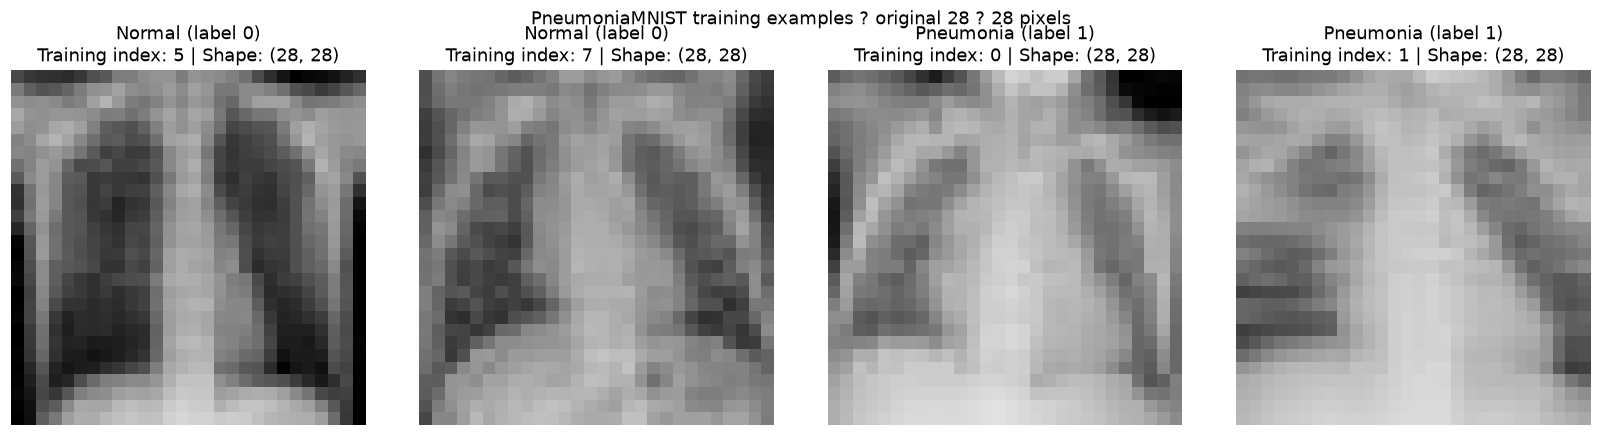

In [6]:
import numpy as np
import matplotlib.pyplot as plt

# Load the extracted training images and their labels.
images = np.load("train_images.npy", allow_pickle=False)
labels = np.load("train_labels.npy", allow_pickle=False).reshape(-1)
class_names = {0: "Normal", 1: "Pneumonia"}

# Choose up to two images from each class (four images in total).
sample_indices = np.concatenate([
    np.flatnonzero(labels == label)[:2] for label in class_names
])

if len(sample_indices) == 0:
    print("No training images available to visualize.")
else:
    fig, axes = plt.subplots(1, len(sample_indices), figsize=(15, 4))
    axes = np.atleast_1d(axes)  # Also works with a single image.

    for ax, image_index in zip(axes, sample_indices):
        image = images[image_index]
        label = int(labels[image_index])
        ax.imshow(image, cmap="gray", vmin=0, vmax=255,
                  interpolation="nearest")
        ax.set_title(f"{class_names[label]} (label {label})\n"
                     f"Training index: {image_index} | Shape: {image.shape}")
        ax.axis("off")

    fig.suptitle("PneumoniaMNIST training examples ? original 28 ? 28 pixels")
    plt.tight_layout()
    plt.show()


## Prepare the CNN inputs

Use the original splits. Normalize once to [0, 1] and add a grayscale channel. A fixed seed helps repeat the experiment; numerical results can still vary across hardware.


In [7]:
from pathlib import Path
import json
import tempfile
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, callbacks
from sklearn.metrics import (accuracy_score, balanced_accuracy_score,
                             confusion_matrix, ConfusionMatrixDisplay, roc_auc_score)
from sklearn.utils.class_weight import compute_class_weight

SEED = 42
keras.utils.set_random_seed(SEED)
ARTIFACT_DIR = Path("cnn_results")
ARTIFACT_DIR.mkdir(exist_ok=True)
# Keep temporary model-save files in a writable project directory.
tempfile.tempdir = str(ARTIFACT_DIR.resolve())

def load_split(split):
    images = np.load(f"{split}_images.npy", allow_pickle=False)
    labels = np.load(f"{split}_labels.npy", allow_pickle=False).reshape(-1)
    if images.shape != (len(labels), 28, 28):
        raise ValueError(f"Unexpected images/labels in {split}")
    if not np.isin(labels, [0, 1]).all():
        raise ValueError(f"Invalid labels in {split}")
    return images.astype("float32")[..., np.newaxis] / 255.0, labels.astype("float32")

x_train, y_train = load_split("train")
x_val, y_val = load_split("val")
x_test, y_test = load_split("test")
for name, images, labels in [("train", x_train, y_train),
                             ("validation", x_val, y_val), ("test", x_test, y_test)]:
    print(f"{name}: images={images.shape}, labels={labels.shape}")
print("Training pixel range:", x_train.min(), "to", x_train.max())

# Limit dataset worker threads to keep CPU training modest.
options = tf.data.Options()
options.threading.private_threadpool_size = 1
options.threading.max_intra_op_parallelism = 1

def make_dataset(images, labels, training=False):
    ds = tf.data.Dataset.from_tensor_slices((images, labels))
    if training:
        ds = ds.shuffle(len(images), seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(32).with_options(options).prefetch(1)

val_ds = make_dataset(x_val, y_val)


train: images=(4708, 28, 28, 1), labels=(4708,)
validation: images=(524, 28, 28, 1), labels=(524,)
test: images=(624, 28, 28, 1), labels=(624,)
Training pixel range: 0.0 to 1.0


## Build a small CNN

Two convolution and pooling blocks learn image patterns. The sigmoid output is a pneumonia score. Binary cross-entropy trains the model against labels 0 and 1.


In [8]:
def build_cnn():
    return keras.Sequential([
        keras.Input(shape=(28, 28, 1)),
        layers.Conv2D(16, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(2),
        layers.Conv2D(32, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(2),
        layers.Flatten(),
        layers.Dense(32, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(1, activation="sigmoid"),
    ], name="pneumonia_cnn")

preview_model = build_cnn()
preview_model.summary(print_fn=lambda line: print(line))


Model: "pneumonia_cnn"
┌─────────────────────────────────┬────────────────────────┬───────────────┐
│ Layer (type)                    │ Output Shape           │       Param # │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 28, 28, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1568)           │             0 │
├─────────────────────────────────┼──────────────────

## Train and compare two candidates

Train at most 30 epochs per candidate, with Adam at 0.001 and batches of 32. Early stopping monitors validation loss with patience 5 and restores the best epoch. Class weights use training labels only. Both candidates start with the same seed. Select using validation balanced accuracy at a fixed 0.5 threshold, breaking ties with validation ROC-AUC. The test set does not enter training or model selection.


In [9]:
classes = np.array([0, 1])
weights = compute_class_weight("balanced", classes=classes, y=y_train.astype("int32"))
class_weights = {int(label): float(weight) for label, weight in zip(classes, weights)}
print("Training-only class weights:", class_weights)

models = {}
histories = {}
validation_results = {}
THRESHOLD = 0.5

for candidate, weighting in [("baseline", None), ("weighted", class_weights)]:
    keras.utils.set_random_seed(SEED)
    candidate_model = build_cnn()
    candidate_model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss="binary_crossentropy",
        metrics=[keras.metrics.BinaryAccuracy(name="accuracy"),
                 keras.metrics.AUC(name="auc")],
    )
    stop = callbacks.EarlyStopping(monitor="val_loss", patience=5,
                                   restore_best_weights=True, verbose=1)
    print(f"\nTraining {candidate} CNN...")
    history = candidate_model.fit(
        make_dataset(x_train, y_train, training=True),
        validation_data=val_ds, epochs=30,
        class_weight=weighting, callbacks=[stop], verbose=2, shuffle=False,
    )
    models[candidate] = candidate_model
    histories[candidate] = history.history
    scores = candidate_model.predict(val_ds, verbose=0).reshape(-1)
    predictions = (scores >= THRESHOLD).astype("int32")
    tn, fp, fn, tp = confusion_matrix(y_val, predictions, labels=[0, 1]).ravel()
    validation_results[candidate] = {
        "balanced_accuracy": float(balanced_accuracy_score(y_val, predictions)),
        "roc_auc": float(roc_auc_score(y_val, scores)),
        "sensitivity": float(tp / (tp + fn)),
        "specificity": float(tn / (tn + fp)),
        "epochs_run": len(history.history["loss"]),
        "best_epoch": int(np.argmin(history.history["val_loss"]) + 1),
    }
    print("Validation results:", validation_results[candidate])

selected_name = max(validation_results, key=lambda name: (
    validation_results[name]["balanced_accuracy"], validation_results[name]["roc_auc"]))
model = models[selected_name]
model.save(ARTIFACT_DIR / "pneumonia_cnn.keras")
print(f"\nSelected {selected_name} using validation data only. Threshold: {THRESHOLD}")


Training-only class weights: {0: 1.9390444810543657, 1: 0.6737263880938752}

Training baseline CNN...
Epoch 1/30
148/148 - 3s - 22ms/step - accuracy: 0.8110 - auc: 0.8325 - loss: 0.4259 - val_accuracy: 0.8721 - val_auc: 0.9623 - val_loss: 0.2773
Epoch 2/30
148/148 - 1s - 8ms/step - accuracy: 0.9087 - auc: 0.9639 - loss: 0.2175 - val_accuracy: 0.9389 - val_auc: 0.9820 - val_loss: 0.1697
Epoch 3/30
148/148 - 1s - 8ms/step - accuracy: 0.9318 - auc: 0.9749 - loss: 0.1779 - val_accuracy: 0.9618 - val_auc: 0.9888 - val_loss: 0.1439
Epoch 4/30
148/148 - 1s - 8ms/step - accuracy: 0.9429 - auc: 0.9800 - loss: 0.1594 - val_accuracy: 0.9599 - val_auc: 0.9893 - val_loss: 0.1235
Epoch 5/30
148/148 - 1s - 9ms/step - accuracy: 0.9416 - auc: 0.9787 - loss: 0.1609 - val_accuracy: 0.9313 - val_auc: 0.9899 - val_loss: 0.1660
Epoch 6/30
148/148 - 1s - 9ms/step - accuracy: 0.9477 - auc: 0.9836 - loss: 0.1444 - val_accuracy: 0.9504 - val_auc: 0.9910 - val_loss: 0.1101
Epoch 7/30
148/148 - 1s - 8ms/step - ac

## Review the learning curves

Inspect training and validation curves for overfitting. Weighted training loss and unweighted validation loss have different weighting, so compare their trends rather than their absolute sizes.


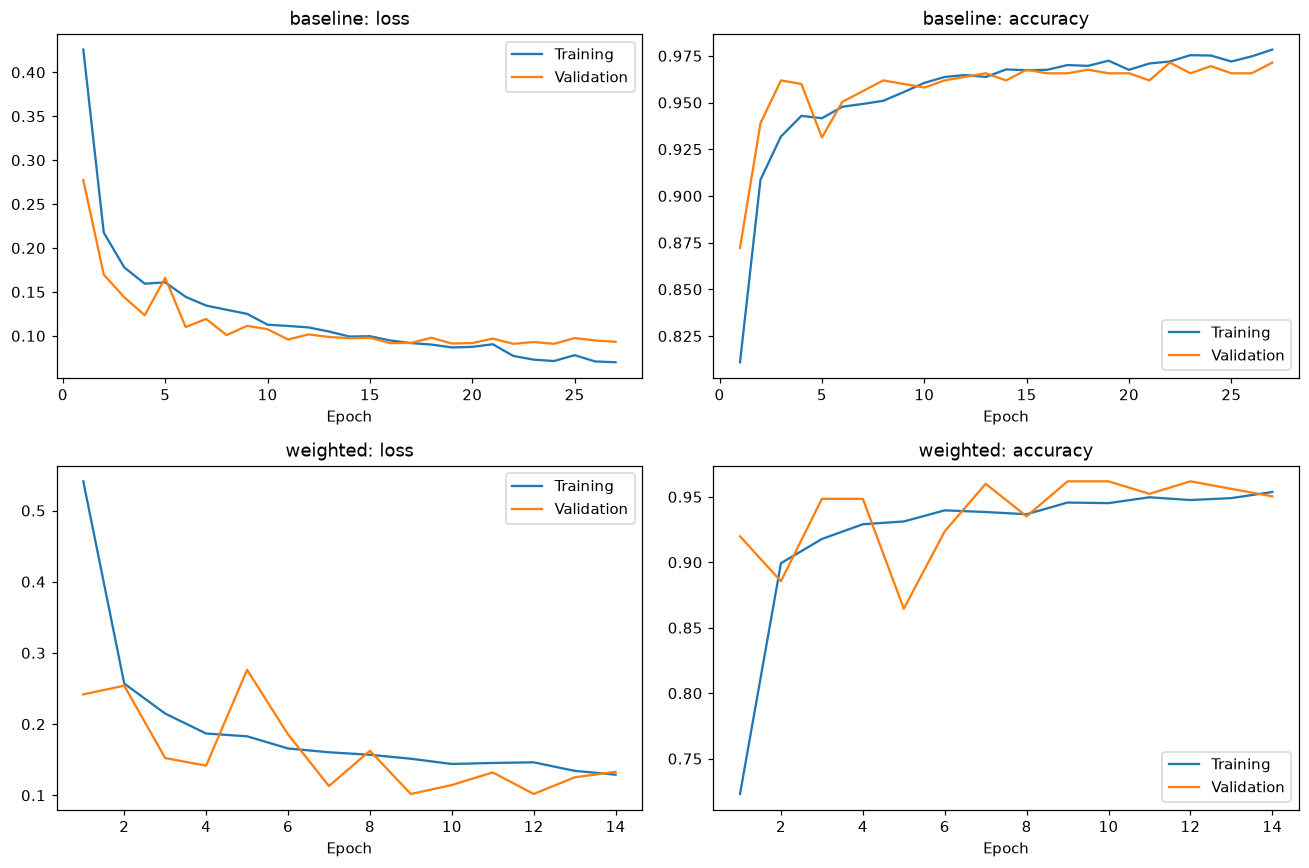

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for row, candidate in enumerate(("baseline", "weighted")):
    h = histories[candidate]
    epochs = range(1, len(h["loss"]) + 1)
    axes[row, 0].plot(epochs, h["loss"], label="Training")
    axes[row, 0].plot(epochs, h["val_loss"], label="Validation")
    axes[row, 0].set_title(f"{candidate}: loss")
    axes[row, 1].plot(epochs, h["accuracy"], label="Training")
    axes[row, 1].plot(epochs, h["val_accuracy"], label="Validation")
    axes[row, 1].set_title(f"{candidate}: accuracy")
    for ax in axes[row]:
        ax.set_xlabel("Epoch")
        ax.legend()
plt.tight_layout()
fig.savefig(ARTIFACT_DIR / "learning_curves.png", dpi=120)
plt.show()


## Final test evaluation

Evaluate the selected model on the untouched test split. Sensitivity measures pneumonia detection; specificity measures normal detection. Keep the 0.5 threshold fixed and do not use these test results to tune the model. This is an educational benchmark, not evidence of hospital readiness.


Selected model: baseline
accuracy: 0.8494
balanced_accuracy: 0.8043
sensitivity: 0.9846
specificity: 0.6239
roc_auc: 0.9432
TN=146, FP=88, FN=6, TP=384
Saved model, metrics, training histories, plots, and test predictions in cnn_results/.


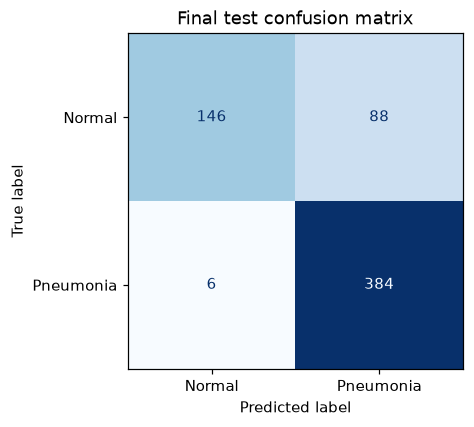

In [11]:
test_ds = make_dataset(x_test, y_test)
test_scores = model.predict(test_ds, verbose=0).reshape(-1)
test_predictions = (test_scores >= THRESHOLD).astype("int32")
cm = confusion_matrix(y_test, test_predictions, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()
test_results = {
    "accuracy": float(accuracy_score(y_test, test_predictions)),
    "balanced_accuracy": float(balanced_accuracy_score(y_test, test_predictions)),
    "sensitivity": float(tp / (tp + fn)),
    "specificity": float(tn / (tn + fp)),
    "roc_auc": float(roc_auc_score(y_test, test_scores)),
    "confusion_matrix": cm.tolist(),
}
print("Selected model:", selected_name)
for metric, value in test_results.items():
    if metric != "confusion_matrix":
        print(f"{metric}: {value:.4f}")
print(f"TN={tn}, FP={fp}, FN={fn}, TP={tp}")
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(cm, display_labels=["Normal", "Pneumonia"]).plot(
    ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Final test confusion matrix")
plt.tight_layout()
fig.savefig(ARTIFACT_DIR / "confusion_matrix.png", dpi=120)
plt.show()

report = {"seed": SEED, "threshold": THRESHOLD,
          "selection_rule": "Validation balanced accuracy, then validation ROC-AUC",
          "selected_model": selected_name, "training_class_weights": class_weights,
          "validation": validation_results, "test": test_results}
(ARTIFACT_DIR / "metrics.json").write_text(json.dumps(report, indent=2), encoding="utf-8")
(ARTIFACT_DIR / "training_history.json").write_text(json.dumps(histories, indent=2), encoding="utf-8")
np.savez_compressed(ARTIFACT_DIR / "test_predictions.npz",
                    labels=y_test, scores=test_scores, predictions=test_predictions)
print("Saved model, metrics, training histories, plots, and test predictions in cnn_results/.")


## Review misclassified test images

Display up to eight mistakes with the stored labels and predicted pneumonia scores. Visual review can suggest questions, but these tiny images cannot establish the medical cause of an error. Do not retrain based on this test review.


Misclassified test images: 94 / 624


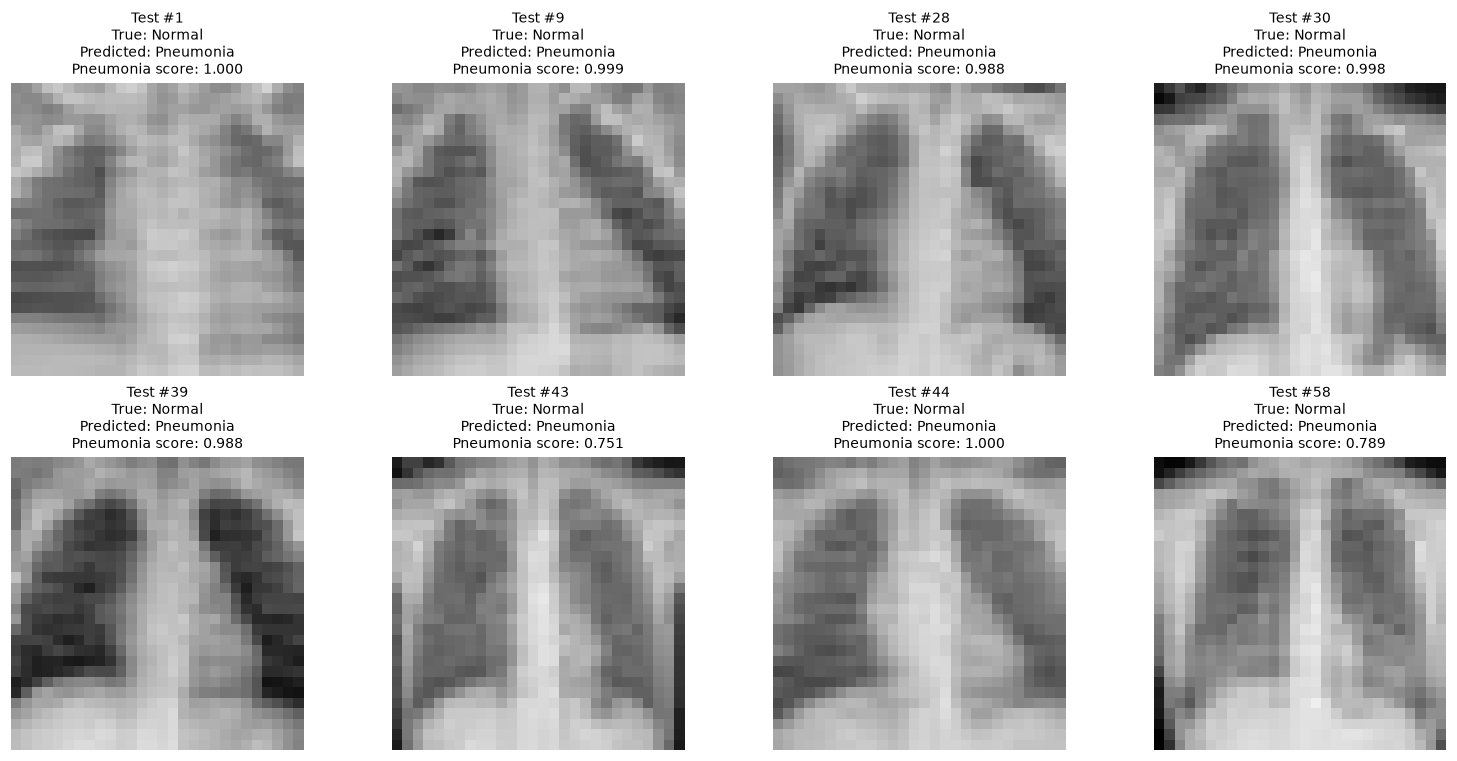

In [12]:
mistakes = np.flatnonzero(test_predictions != y_test.astype("int32"))
print(f"Misclassified test images: {len(mistakes)} / {len(y_test)}")
if len(mistakes):
    examples = mistakes[:8]
    names = {0: "Normal", 1: "Pneumonia"}
    fig, axes = plt.subplots(2, 4, figsize=(14, 7))
    for ax in axes.flat:
        ax.axis("off")
    for ax, index in zip(axes.flat, examples):
        ax.imshow(x_test[index, ..., 0], cmap="gray", vmin=0, vmax=1,
                  interpolation="nearest")
        ax.set_title(f"Test #{index}\nTrue: {names[int(y_test[index])]}\n"
                     f"Predicted: {names[int(test_predictions[index])]}\n"
                     f"Pneumonia score: {test_scores[index]:.3f}", fontsize=9)
    plt.tight_layout()
    fig.savefig(ARTIFACT_DIR / "misclassified_images.png", dpi=120)
    plt.show()
else:
    print("No misclassified images at the fixed threshold.")


## Test the saved model without retraining

Run this cell independently to load `cnn_results/pneumonia_cnn.keras`, classify every test image, and view example predictions. This repeats the existing final evaluation with the same model and threshold; it is not a new independent test. Scores are model outputs, not calibrated clinical probabilities.


Saved model: cnn_results\pneumonia_cnn.keras
Test images: 624
Accuracy: 84.94%
Balanced accuracy: 80.43%
Sensitivity: 98.46%
Specificity: 62.39%
ROC-AUC: 0.9432
Correct: 530; incorrect: 94
TN=146, FP=88, FN=6, TP=384


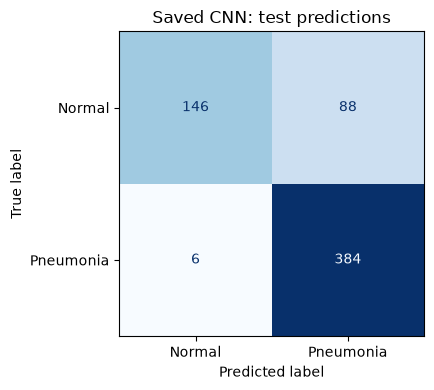

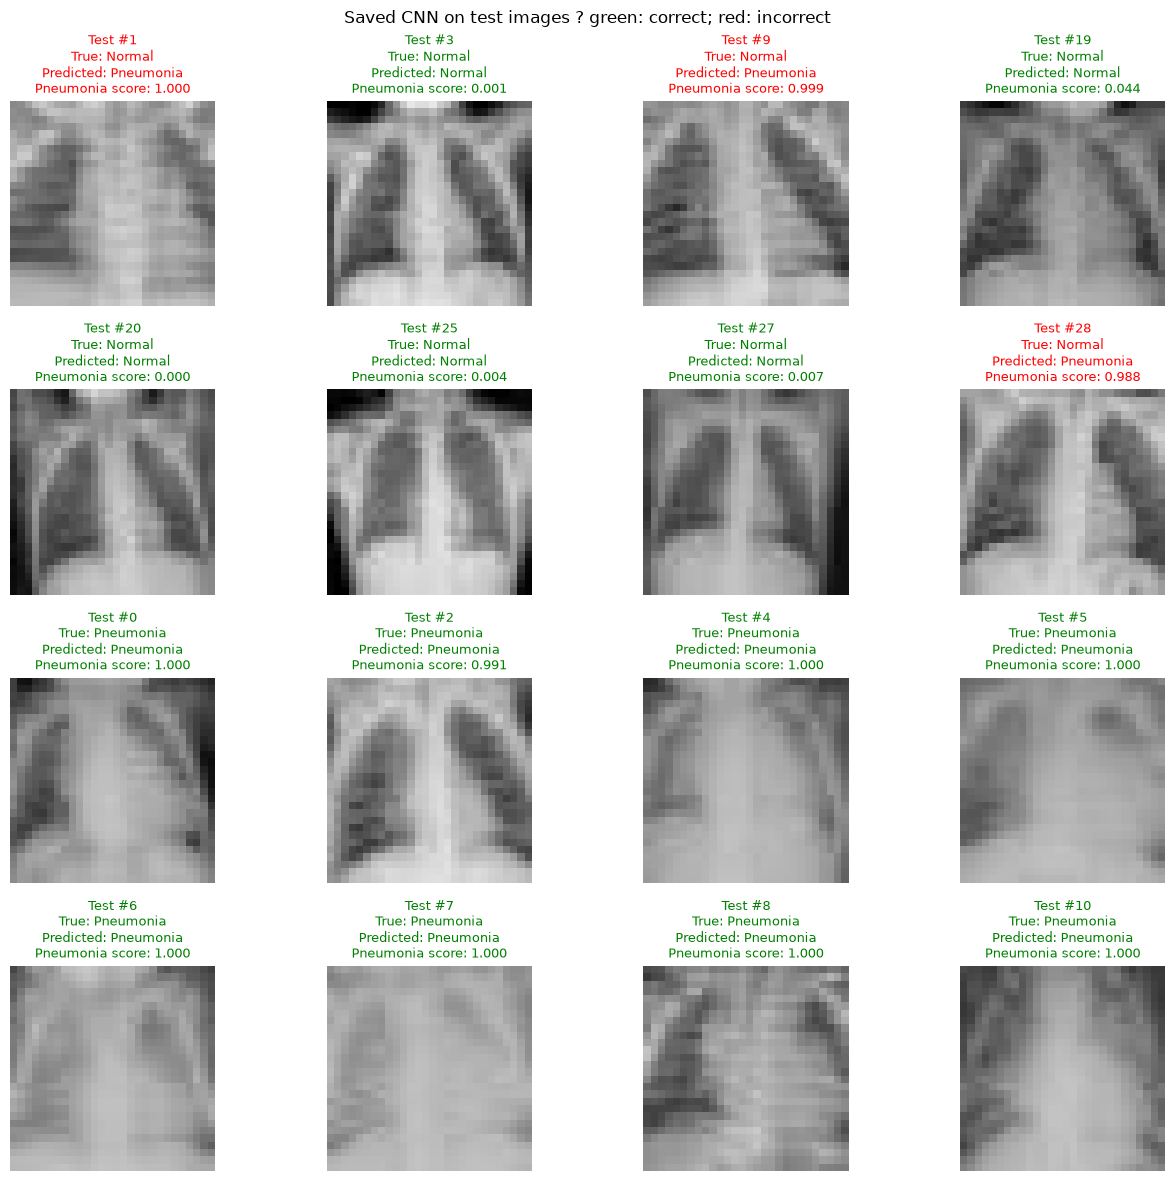

In [1]:
# Test the saved CNN without retraining it.
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from tensorflow import keras
from sklearn.metrics import (accuracy_score, balanced_accuracy_score,
                             confusion_matrix, ConfusionMatrixDisplay, roc_auc_score)

model_path = Path("cnn_results/pneumonia_cnn.keras")
saved_model = keras.models.load_model(model_path, compile=False)
test_images = np.load("test_images.npy", allow_pickle=False)
test_labels = np.load("test_labels.npy", allow_pickle=False).reshape(-1)
if len(test_images) != len(test_labels):
    raise ValueError("Test image and label counts do not match.")

# Use the same normalization and channel shape as training.
test_inputs = test_images.astype("float32")[..., np.newaxis] / 255.0
scores = np.concatenate([
    saved_model(test_inputs[start:start + 32], training=False).numpy().reshape(-1)
    for start in range(0, len(test_inputs), 32)
])
threshold = 0.5  # Keep the threshold used in the original final evaluation.
predictions = (scores >= threshold).astype("int32")
matrix = confusion_matrix(test_labels, predictions, labels=[0, 1])
tn, fp, fn, tp = matrix.ravel()
print("Saved model:", model_path)
print("Test images:", len(test_labels))
print(f"Accuracy: {accuracy_score(test_labels, predictions):.2%}")
print(f"Balanced accuracy: {balanced_accuracy_score(test_labels, predictions):.2%}")
print(f"Sensitivity: {tp / (tp + fn):.2%}")
print(f"Specificity: {tn / (tn + fp):.2%}")
print(f"ROC-AUC: {roc_auc_score(test_labels, scores):.4f}")
print(f"Correct: {tn + tp}; incorrect: {fp + fn}")
print(f"TN={tn}, FP={fp}, FN={fn}, TP={tp}")

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(matrix, display_labels=["Normal", "Pneumonia"]).plot(
    ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Saved CNN: test predictions")
plt.tight_layout()
plt.show()

# Display eight examples from each true class, not cherry-picked by prediction.
indices = np.concatenate([np.flatnonzero(test_labels == label)[:8] for label in (0, 1)])
class_names = {0: "Normal", 1: "Pneumonia"}
fig, axes = plt.subplots(4, 4, figsize=(13, 12))
for ax in axes.flat:
    ax.axis("off")
for ax, index in zip(axes.flat, indices):
    correct = predictions[index] == test_labels[index]
    ax.imshow(test_images[index], cmap="gray", vmin=0, vmax=255,
              interpolation="nearest")
    ax.set_title(f"Test #{index}\nTrue: {class_names[int(test_labels[index])]}\n"
                 f"Predicted: {class_names[int(predictions[index])]}\n"
                 f"Pneumonia score: {scores[index]:.3f}",
                 color="green" if correct else "red", fontsize=9)
fig.suptitle("Saved CNN on test images ? green: correct; red: incorrect")
plt.tight_layout()
fig.savefig("cnn_results/saved_model_test_examples.png", dpi=110)
plt.show()
